# coach — report figures

Five figures for `report.tex`, one per section that has math in it: the
temporal smoothing (§3), the first-pull diagnostic (§4.1.1), the second-pull
diagnostic (§4.1.2), and the two depth-lift figures in Appendix A. Every number here comes from a **Python port of the
browser code** — `smoothKeypoints` / `retimeAlongPath` / `gauss1d` from
`app.py`, and the track preparation, triggers and measures from
`diagnostics.js`. The port is line-for-line on purpose: if the JS changes, this
file is wrong until it is changed the same way. Constants are named as in the
source so a diff is easy.

The track comes from `examples/athlete-a-trim.track.json`, which
`extract_track.py` writes by running the real pipeline (YOLOv8 → ViTPose-L →
SORT → main-person filter) in the `coach` conda env. This notebook itself
needs only numpy + matplotlib and will call the extractor if the cache is
missing.

In [1]:
import json, math, subprocess, sys
from pathlib import Path
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

HERE = Path.cwd()
CLIP = HERE / 'examples' / 'athlete-a-trim.mp4'
TRACK = CLIP.with_suffix('.track.json')
FIG = HERE / 'figures'; FIG.mkdir(exist_ok=True)
COACH_PY = Path.home() / 'anaconda3/envs/coach/bin/python'

if not TRACK.exists():
    subprocess.run([str(COACH_PY), str(HERE / 'extract_track.py'), str(CLIP), 'l'], check=True)
data = json.loads(TRACK.read_text())
RAW, META = data['keypoints'], data['meta']
PID = str(META['tracks']['kept'])
print(f"{META['frames_processed']} frames @ {META['fps']:.2f} fps, {META['width']}x{META['height']}, person {PID}, "
      f"dropped {[d['id'] for d in META['tracks']['dropped']]}")

107 frames @ 30.00 fps, 1080x1920, person 1, dropped ['15', '6', '21', '9', '11', '2', '13', '22', '27', '16', '24', '26']


## Figure style

Light-surface instance of the dataviz palette (validated: blue/orange pass every
gate on white). Two conventions are carried over from the app itself so the
figures read like its plots: the **phase** is a purple wash with a hairline at
each edge (a boundary, not a score), and a single-series plot gets no legend.

In [2]:
C = dict(blue='#2a78d6', orange='#eb6834', aqua='#1baf7a',
         ink='#0b0b0b', ink2='#52514e', muted='#898781', grid='#e1e0d9', axis='#c3c2b7',
         phase='#b39ddb')
mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.size': 8.5,
    'axes.edgecolor': C['axis'], 'axes.labelcolor': C['ink2'], 'axes.titlesize': 9,
    'axes.titleweight': 'normal', 'axes.titlecolor': C['ink'], 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': C['grid'], 'grid.linewidth': 0.6,
    'xtick.color': C['muted'], 'ytick.color': C['muted'], 'xtick.labelcolor': C['ink2'], 'ytick.labelcolor': C['ink2'],
    'xtick.major.size': 0, 'ytick.major.size': 0,
    'lines.linewidth': 1.6, 'lines.solid_joinstyle': 'round', 'lines.solid_capstyle': 'round',
    'legend.frameon': False, 'legend.fontsize': 8, 'legend.labelcolor': C['ink2'],
    'figure.dpi': 130, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
    'pdf.fonttype': 42,
})
TEXTW = 6.55   # inches, the report's text width at 2.2 cm margins

def phase_band(ax, t0, t1, label=None, pos='top'):
    ax.axvspan(t0, t1, color=C['phase'], alpha=0.16, lw=0, zorder=0)
    for t in (t0, t1):
        ax.axvline(t, color=C['phase'], lw=0.8, zorder=1)
    if label:   # inside the band (never on the title row); top or bottom, whichever is free
        y, va = (0.97, 'top') if pos == 'top' else (0.03, 'bottom')
        ax.text((t0 + t1) / 2, y, label, transform=ax.get_xaxis_transform(),
                ha='center', va=va, fontsize=7.5, color=C['ink2'])

def title_legend(ax, ncol=2, **kw):
    # legend on the title row, right-aligned: never on top of the data
    ax.legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), ncol=ncol, borderaxespad=0, handlelength=1.6, **kw)

def ref_line(ax, y, label, x, ha='left', va='bottom'):
    ax.axhline(y, color=C['ink2'], lw=0.8, ls=(0, (4, 3)), zorder=1)
    ax.text(x, y, label, ha=ha, va=va, fontsize=7.5, color=C['ink2'])

## Port of `app.py`: temporal smoothing

`sampleTimes`, `smoothKeypoints` (confidence-weighted Gaussian in time,
truncated at 3σ, sub-threshold neighbours excluded, own confidence kept),
`gauss1d`, and `retimeAlongPath` (the velocity filter). Keypoints stay in the
backend's `[y, x, conf]` layout throughout.

In [3]:
CONF_THRESHOLD = 0.3
SIGMA_CUTOFF = 3
E_FINE, E_COARSE = 0.5, 4

def sample_times(meta, kp):
    frames = meta['frame_indices'] if meta.get('frame_indices') else sorted(int(f) for f in kp)
    ft = meta.get('frame_times_ms')
    times = [ft[s] / 1000 if ft and ft[s] is not None else f / (meta['fps'] or 30) for s, f in enumerate(frames)]
    return frames, times

def gauss1d(v, T, s):
    n = len(v); out = np.array(v, dtype=float).copy()
    if not s > 0: return out
    cutoff, denom = SIGMA_CUTOFF * s, 2 * s * s
    for k in range(n):
        acc = w = 0.0
        for j in range(k, n):
            dt = T[j] - T[k]
            if dt > cutoff: break
            g = math.exp(-dt * dt / denom); acc += g * v[j]; w += g
        for j in range(k - 1, -1, -1):
            dt = T[k] - T[j]
            if dt > cutoff: break
            g = math.exp(-dt * dt / denom); acc += g * v[j]; w += g
        out[k] = acc / w if w > 0 else v[k]
    return out

def retime_along_path(R, P, T, sigma):
    n = len(P)
    A = np.zeros(n); ty = np.zeros(n); tx = np.zeros(n)
    for m in range(1, n):
        dy, dx = P[m][0] - P[m-1][0], P[m][1] - P[m-1][1]
        ln = math.hypot(dy, dx); A[m] = A[m-1] + ln
        if ln > 1e-9: ty[m], tx[m] = dy / ln, dx / ln
    e = np.zeros(n); prog = 0.0
    for m in range(1, n):
        prog += (R[m][0] - R[m-1][0]) * ty[m] + (R[m][1] - R[m-1][1]) * tx[m]
        e[m] = prog - A[m]
    fine, coarse = gauss1d(e, T, sigma * E_FINE), gauss1d(e, T, sigma * E_COARSE)
    total = A[n-1]; Q = [None] * n
    for m in range(n):
        target = max(0.0, min(total, A[m] + (fine[m] - coarse[m])))
        s = int(np.searchsorted(A, target, side='right') - 1); s = max(0, min(s, n - 2))
        seg = A[s+1] - A[s]; u = (target - A[s]) / seg if seg > 1e-9 else 0.0
        Q[m] = [P[s][0] + u * (P[s+1][0] - P[s][0]), P[s][1] + u * (P[s+1][1] - P[s][1]), P[m][2]]
    return Q, dict(A=A, e=e, fine=fine, coarse=coarse)

def smooth_keypoints(raw, meta, sigma, keep_velocity, debug=None):
    if not sigma > 0: return raw
    frames, times = sample_times(meta, raw)
    cutoff, denom = SIGMA_CUTOFF * sigma, 2 * sigma * sigma
    out = {}
    for k, f in enumerate(frames):
        src = raw.get(str(f))
        if src is None: continue
        dst = out[str(f)] = {}
        for pid, points in src.items():
            res = []
            for i, pt in enumerate(points):
                if pt is None or pt[2] < CONF_THRESHOLD: res.append(pt); continue
                sy = sx = w = 0.0
                for d in (1, -1):
                    j = k
                    while 0 <= j < len(frames):
                        if not (d == -1 and j == k):
                            dt = abs(times[j] - times[k])
                            if dt > cutoff: break
                            q = raw.get(str(frames[j]), {}).get(pid)
                            q = q[i] if q else None
                            if q is not None and q[2] >= CONF_THRESHOLD:
                                g = math.exp(-dt * dt / denom) * q[2]
                                sy += g * q[0]; sx += g * q[1]; w += g
                        j += d
                res.append([sy / w, sx / w, pt[2]] if w > 0 else pt)
            dst[pid] = res
    if not keep_velocity: return out
    ids = {pid for f in frames for pid in out.get(str(f), {})}
    for pid in ids:
        n_kp = next(len(out[str(f)][pid]) for f in frames if pid in out.get(str(f), {}))
        for i in range(n_kp):
            ks = [k for k, f in enumerate(frames)
                  if (q := raw.get(str(f), {}).get(pid)) and q[i][2] >= CONF_THRESHOLD]
            if len(ks) < 3: continue
            R = [raw[str(frames[k])][pid][i] for k in ks]
            P = [out[str(frames[k])][pid][i] for k in ks]
            T = [times[k] for k in ks]
            Q, dbg = retime_along_path(R, P, T, sigma)
            if debug is not None: debug[(pid, i)] = dict(ks=ks, T=T, **dbg)
            for m, k in enumerate(ks): out[str(frames[k])][pid][i] = Q[m]
    return out

## Port of `diagnostics.js`: track preparation, geometry, phases, measures

Same constants, same names. `prepare_points` gates at `DIAG_CONF` and fills
holes with a 5-sample mean (flagged `interp`); it deliberately does **not**
smooth again. Everything in pixels is normalized by `torso_scale`.

In [4]:
KP = dict(lSho=5, rSho=6, lElb=7, rElb=8, lWri=9, rWri=10, lHip=11, rHip=12, lKnee=13, rKnee=14, lAnk=15, rAnk=16)
USED = list(KP.values())
DIAG_CONF, FILL_WIN = 0.3, 5
SPEED_SMOOTH, SPEED_HALF, RUN = 9, 2, 3
MOVE_ONSET = 0.15
EXT_CONFIRM_RISE = 0.08

def build_track(kp_by_frame, meta, pid):
    frames, times = sample_times(meta, kp_by_frame)
    samples = []
    for slot, f in enumerate(frames):
        kp = kp_by_frame.get(str(f), {}).get(pid)
        if kp: samples.append(dict(frame=f, t=times[slot], kp=kp))
    return samples

def prepare_points(samples):
    for s in samples:
        s['raw'] = {i: (dict(x=q[1], y=q[0], c=q[2]) if (q := s['kp'][i]) and q[2] >= DIAG_CONF else None) for i in USED}
    half = (FILL_WIN - 1) >> 1
    for k, s in enumerate(samples):
        p = {}
        for i in USED:
            here = s['raw'][i]
            if here: p[i] = dict(x=here['x'], y=here['y'], interp=False); continue
            pts = [q for j in range(max(0, k - half), min(len(samples) - 1, k + half) + 1) if (q := samples[j]['raw'][i])]
            p[i] = dict(x=np.mean([q['x'] for q in pts]), y=np.mean([q['y'] for q in pts]), interp=True) if pts else None
        s['p'] = p

def torso_scale(samples):
    d = []
    for s in samples:
        v = [math.hypot(a['x'] - b['x'], a['y'] - b['y']) for h, sh in ((KP['lHip'], KP['lSho']), (KP['rHip'], KP['rSho']))
             if (a := s['p'][h]) and (b := s['p'][sh])]
        if v: d.append(np.mean(v))
    return float(sorted(d)[len(d) >> 1]) if d else None

def bar_point(p):
    est, no_forearm = [], False
    for w, e in ((KP['lWri'], KP['lElb']), (KP['rWri'], KP['rElb'])):
        pw = p[w]
        if not pw: continue
        pe = p[e]
        if pe: est.append((pw['x'], pw['y'] + math.hypot(pw['x'] - pe['x'], pw['y'] - pe['y']) / 6))
        else: est.append((pw['x'], pw['y'])); no_forearm = True
    if not est: return None
    return dict(x=np.mean([e[0] for e in est]), y=np.mean([e[1] for e in est]), sides=len(est), noForearm=no_forearm)

def mean_of(p, idxs, key):
    v = [p[i][key] for i in idxs if p[i]]
    return float(np.mean(v)) if v else None

knee_y = lambda p: mean_of(p, [KP['lKnee'], KP['rKnee']], 'y')
hip_elevation = lambda p: mean_of(p, [KP['lHip'], KP['rHip']], 'y')
def wrist_centroid(p):
    x, y = mean_of(p, [KP['lWri'], KP['rWri']], 'x'), mean_of(p, [KP['lWri'], KP['rWri']], 'y')
    return None if x is None or y is None else dict(x=x, y=y)

def trunk_angle(hip, sho):
    if not hip or not sho: return None
    return math.degrees(math.atan2(hip['y'] - sho['y'], abs(sho['x'] - hip['x'])))

def joint_angle(joint, a, b):
    if not joint or not a or not b: return None
    v1 = (a['x'] - joint['x'], a['y'] - joint['y']); v2 = (b['x'] - joint['x'], b['y'] - joint['y'])
    m1, m2 = math.hypot(*v1), math.hypot(*v2)
    if not m1 or not m2: return None
    return math.degrees(math.acos(max(-1, min(1, (v1[0] * v2[0] + v1[1] * v2[1]) / (m1 * m2)))))

def smooth_series(raw):
    half = (SPEED_SMOOTH - 1) >> 1
    out = []
    for k in range(len(raw)):
        v = [raw[j] for j in range(max(0, k - half), min(len(raw) - 1, k + half) + 1) if raw[j] is not None]
        out.append(float(np.mean(v)) if v else None)
    return out

def wrist_speed(samples, scale):
    raw = [wrist_centroid(s['p']) for s in samples]
    half = (SPEED_SMOOTH - 1) >> 1
    c = []
    for k in range(len(raw)):
        v = [raw[j] for j in range(max(0, k - half), min(len(raw) - 1, k + half) + 1) if raw[j]]
        c.append(dict(x=np.mean([q['x'] for q in v]), y=np.mean([q['y'] for q in v])) if v else None)
    out = [None] * len(samples)
    for i in range(SPEED_HALF, len(samples) - SPEED_HALF):
        a, b = c[i - SPEED_HALF], c[i + SPEED_HALF]
        dt = samples[i + SPEED_HALF]['t'] - samples[i - SPEED_HALF]['t']
        if a and b and dt > 0: out[i] = math.hypot(b['x'] - a['x'], b['y'] - a['y']) / dt / scale
    return out

def bar_knee_crossing(samples):
    bar = [bar_point(s['p']) for s in samples]; knee = [knee_y(s['p']) for s in samples]
    above = lambda i: bool(bar[i]) and knee[i] is not None and bar[i]['y'] < knee[i]
    below = lambda i: bool(bar[i]) and knee[i] is not None and bar[i]['y'] > knee[i]
    first = next((i for i in range(len(samples)) if below(i)), -1)
    if first < 0: return dict(bar=bar, knee=knee, idx=-1, reason='no-below')
    for i in range(first + 1, len(samples)):
        if above(i) and all(above(j) for j in range(i, min(i + RUN, len(samples)))):
            return dict(bar=bar, knee=knee, idx=i, reason=None)
    return dict(bar=bar, knee=knee, idx=-1, reason='no-cross')

# --- diagnostic 1: first pull, constant back angle
def first_pull_phase(samples, scale):
    cross = bar_knee_crossing(samples)
    assert cross['idx'] >= 0, cross['reason']
    end = cross['idx']; speed = wrist_speed(samples, scale)
    start = -1
    for i in range(end - 1, RUN - 2, -1):
        if all(speed[i - j] is not None and speed[i - j] < MOVE_ONSET for j in range(RUN)): start = i; break
    clamped = start < 0
    if clamped: start = 0
    onset = next((speed[i] for i in range(start + 1, end + 1) if speed[i] is not None and speed[i] >= MOVE_ONSET), None)
    return dict(startIdx=start, endIdx=end, clamped=clamped, onsetSpeed=onset, speed=speed, **cross)

def trunk_series(samples, lo, hi):
    out = []
    for i in range(lo, hi + 1):
        p = samples[i]['p']
        aL, aR = trunk_angle(p[KP['lHip']], p[KP['lSho']]), trunk_angle(p[KP['rHip']], p[KP['rSho']])
        vals = [v for v in (aL, aR) if v is not None]
        if vals: out.append(dict(idx=i, t=samples[i]['t'], value=np.mean(vals), lo=min(vals), hi=max(vals)))
    return out

def first_pull_measure(samples, ph):
    series = trunk_series(samples, ph['startIdx'], ph['endIdx'])
    vals = np.array([s['value'] for s in series])
    return dict(series=series, mean=vals.mean(), sd=vals.std(), drift=vals[-1] - vals[0],
                spread=np.mean([s['hi'] - s['lo'] for s in series]))

# --- diagnostic 2: second pull, full triple extension
def second_pull_phase(samples, scale):
    cross = bar_knee_crossing(samples)
    assert cross['idx'] >= 0
    start = cross['idx']
    elev = smooth_series([hip_elevation(s['p']) for s in samples])
    best_i, best_y, end = -1, math.inf, -1
    for i in range(start, len(samples)):
        if elev[i] is None: continue
        if elev[i] < best_y: best_y, best_i = elev[i], i; continue
        if best_i < 0 or elev[i] - best_y <= EXT_CONFIRM_RISE * scale: continue
        if all(elev[j] is not None and elev[j] - best_y > EXT_CONFIRM_RISE * scale for j in range(i, min(i + RUN, len(samples)))):
            end = best_i; break
    confirmed = end >= 0
    if not confirmed: end = best_i
    return dict(startIdx=start, endIdx=end, peakElevPx=best_y, confirmed=confirmed, elev=elev, **cross)

def joint_series(samples, lo, hi):
    hip, knee = [], []
    for i in range(lo, hi + 1):
        p = samples[i]['p']
        hL = joint_angle(p[KP['lHip']], p[KP['lSho']], p[KP['lKnee']]); hR = joint_angle(p[KP['rHip']], p[KP['rSho']], p[KP['rKnee']])
        hv = [v for v in (hL, hR) if v is not None]
        if not hv: continue
        hip.append(dict(t=samples[i]['t'], value=np.mean(hv), lo=min(hv), hi=max(hv)))
        kL = joint_angle(p[KP['lKnee']], p[KP['lHip']], p[KP['lAnk']]); kR = joint_angle(p[KP['rKnee']], p[KP['rHip']], p[KP['rAnk']])
        kv = [v for v in (kL, kR) if v is not None]
        knee.append(dict(t=samples[i]['t'], value=np.mean(kv) if kv else None))
    return hip, knee

def second_pull_measure(samples, ph):
    hip, knee = joint_series(samples, ph['startIdx'], ph['endIdx'])
    tail = min(3, len(hip))
    hip_peak = np.mean([s['value'] for s in hip[-tail:]])
    kt = [s['value'] for s in knee[-tail:] if s['value'] is not None]
    knee_peak = np.mean(kt) if kt else None
    hi = max(range(len(hip)), key=lambda k: hip[k]['value'])
    kk = [k for k in range(len(knee)) if knee[k]['value'] is not None]
    ki = max(kk, key=lambda k: knee[k]['value']) if kk else None
    return dict(hip=hip, knee=knee, hipPeak=hip_peak, kneePeak=knee_peak,
                hipDeficit=180 - hip_peak, kneeDeficit=None if knee_peak is None else 180 - knee_peak,
                syncGap=None if ki is None else abs(hip[hi]['t'] - knee[ki]['t']),
                hipPeakT=hip[hi]['t'], kneePeakT=None if ki is None else knee[ki]['t'])

## Run the pipeline at the app's defaults (σ = 50 ms, velocity preserved)

In [5]:
SIGMA = 0.050
dbg = {}
SMOOTH = smooth_keypoints(RAW, META, SIGMA, keep_velocity=True, debug=dbg)
GAUSS = smooth_keypoints(RAW, META, SIGMA, keep_velocity=False)

samples = build_track(SMOOTH, META, PID); prepare_points(samples)
L = torso_scale(samples)
ph1 = first_pull_phase(samples, L); m1 = first_pull_measure(samples, ph1)
ph2 = second_pull_phase(samples, L); m2 = second_pull_measure(samples, ph2)
T = np.array([s['t'] for s in samples])
t_at = lambda i: samples[i]['t']

print(f"torso scale L = {L:.1f} px, {len(samples)} samples")
print(f"first pull : frames {samples[ph1['startIdx']]['frame']}–{samples[ph1['endIdx']]['frame']}, "
      f"clamped={ph1['clamped']}, onset {ph1['onsetSpeed']:.2f} L/s | mean {m1['mean']:.1f}°, SD {m1['sd']:.2f}°, "
      f"drift {m1['drift']:+.1f}°, L/R {m1['spread']:.1f}°")
print(f"second pull: frames {samples[ph2['startIdx']]['frame']}–{samples[ph2['endIdx']]['frame']}, confirmed={ph2['confirmed']} | "
      f"hip {m2['hipDeficit']:.1f}° short, knee {None if m2['kneeDeficit'] is None else round(m2['kneeDeficit'],1)}° short, "
      f"sync {None if m2['syncGap'] is None else round(m2['syncGap']*1000)} ms")

torso scale L = 215.6 px, 107 samples
first pull : frames 0–14, clamped=True, onset 0.28 L/s | mean 47.6°, SD 11.79°, drift -30.5°, L/R 4.5°
second pull: frames 14–27, confirmed=True | hip 14.3° short, knee 20.7° short, sync 67 ms


## Figure 1 — smoothing and the velocity filter

One wrist keypoint (whichever side the model was more confident about). Top:
the trajectory's vertical coordinate, raw vs Gaussian vs Gaussian + retiming —
the retimed curve lies *on* the Gaussian path (it is a reparametrization) but
reaches each height at the raw track's time. Middle: speed along the track,
where the Gaussian's attenuation of the pull and the retiming's recovery of it
are visible directly. Bottom: the residual $e = \Pi - A$ that drives the
retiming, and its band-passed version $\hat e$ that is actually applied.

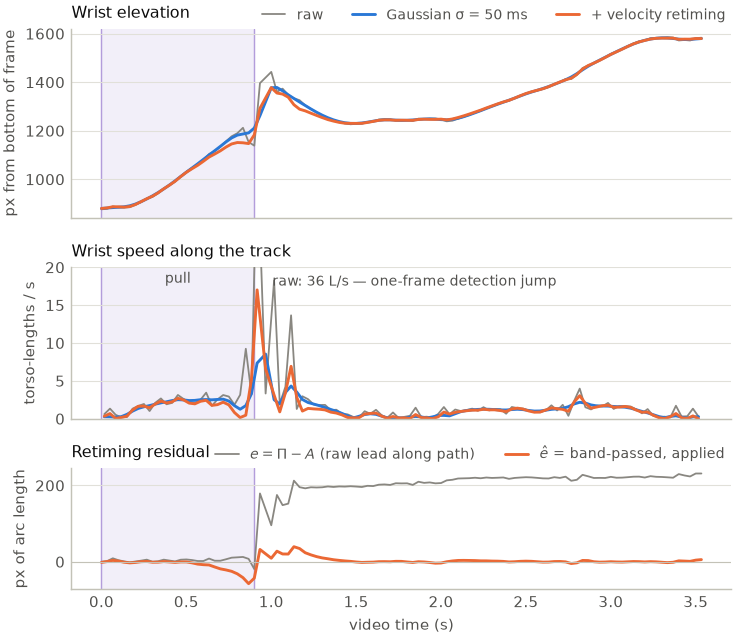

peak wrist speed inside the pull [L/s]: {'raw': np.float64(9.24), 'gauss': np.float64(3.3), 'retimed': np.float64(5.21)} | gauss/raw = 0.36  retimed/raw = 0.56


In [6]:
def kp_series(track, i):
    fr, tm = sample_times(META, track)
    t, y, x = [], [], []
    for s, f in enumerate(fr):
        q = track.get(str(f), {}).get(PID)
        if q and q[i][2] >= CONF_THRESHOLD: t.append(tm[s]); y.append(q[i][0]); x.append(q[i][1])
    return np.array(t), np.array(y), np.array(x)

def speed_of(t, y, x):
    d = np.hypot(np.diff(y), np.diff(x)) / np.diff(t) / L
    return (t[1:] + t[:-1]) / 2, d

conf = {i: np.mean([q[i][2] for f in RAW.values() if (q := f.get(PID))]) for i in (KP['lWri'], KP['rWri'])}
WRIST = max(conf, key=conf.get)
series = {k: kp_series(tr, WRIST) for k, tr in (('raw', RAW), ('gauss', GAUSS), ('retimed', SMOOTH))}
d = dbg[(PID, WRIST)]

fig, ax = plt.subplots(3, 1, figsize=(TEXTW, 5.6), sharex=True, gridspec_kw=dict(hspace=0.32, height_ratios=[1.25, 1, 0.8]))
H = META['height']
style = dict(raw=dict(color=C['muted'], lw=1.0, label='raw'),
             gauss=dict(color=C['blue'], label=f'Gaussian σ = {SIGMA*1000:.0f} ms'),
             retimed=dict(color=C['orange'], label='+ velocity retiming'))
for k in ('raw', 'gauss', 'retimed'):
    t, y, x = series[k]
    ax[0].plot(t, H - y, **style[k])
    ts, v = speed_of(t, y, x)
    ax[1].plot(ts, v, **style[k])
ax[0].set_title('Wrist elevation'); ax[0].set_ylabel('px from bottom of frame')
ax[1].set_title('Wrist speed along the track'); ax[1].set_ylabel('torso-lengths / s')
# the raw track jumps ~250 px in one frame at the turnover (a detection jump, not motion);
# it would set the whole axis, so the axis is capped and the jump is stated instead
_, vr = speed_of(*series['raw']); ax[1].set_ylim(0, 20)
ax[1].annotate(f'raw: {vr.max():.0f} L/s — one-frame detection jump', (series['raw'][0][vr.argmax()], 19.5),
               (10, -2), textcoords='offset points', ha='left', va='top', fontsize=7.5, color=C['ink2'])
title_legend(ax[0], ncol=3)
ax[2].plot(d['T'], d['e'], color=C['muted'], lw=1.0, label='$e = \\Pi - A$ (raw lead along path)')
ax[2].plot(d['T'], d['fine'] - d['coarse'], color=C['orange'], label='$\\hat e$ = band-passed, applied')
ax[2].axhline(0, color=C['axis'], lw=0.6)
ax[2].set_title('Retiming residual'); ax[2].set_ylabel('px of arc length'); ax[2].set_xlabel('video time (s)')
title_legend(ax[2])
for k, a in enumerate(ax): phase_band(a, t_at(ph1['startIdx']), t_at(ph2['endIdx']), 'pull' if k == 1 else None)
fig.savefig(FIG / 'smoothing.pdf'); plt.show()

# attenuation measured on this clip, inside the pull only (the raw spike at the turnover is a
# detection jump and would make the ratio meaningless)
w0, w1 = t_at(ph1['startIdx']), t_at(ph2['endIdx'])
pk = {}
for k in series:
    ts, v = speed_of(*series[k]); pk[k] = v[(ts >= w0) & (ts <= w1)].max()
print('peak wrist speed inside the pull [L/s]:', {k: round(v, 2) for k, v in pk.items()},
      '| gauss/raw =', round(pk['gauss'] / pk['raw'], 2), ' retimed/raw =', round(pk['retimed'] / pk['raw'], 2))

## Figure 2 — first pull: triggers and measurement

Top: the two heights the end trigger compares — the estimated bar (wrist + ⅙
forearm) and the knee — over the whole clip; the phase ends where the bar
first clears the knee for `RUN` samples. Middle: the wrist-centroid speed the
start trigger searches backwards through for the last `RUN`-sample window
under `MOVE_ONSET`. Bottom: the trunk angle with its L/R band and the phase
mean; SD and drift are read off the shaded window only.

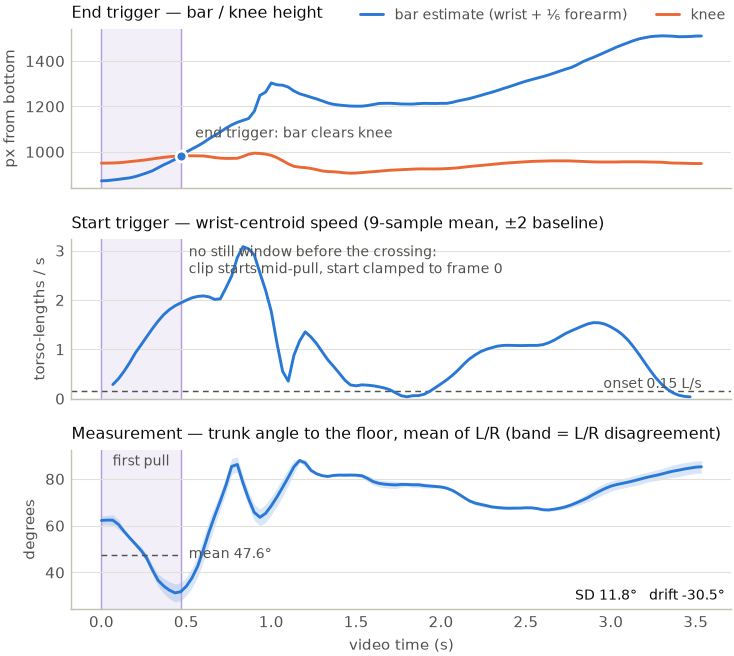

In [7]:
t0, t1 = t_at(ph1['startIdx']), t_at(ph1['endIdx'])
full = trunk_series(samples, 0, len(samples) - 1)
ft = np.array([s['t'] for s in full]); fv = np.array([s['value'] for s in full])
flo = np.array([s['lo'] for s in full]); fhi = np.array([s['hi'] for s in full])
bar_y = np.array([b['y'] if b else np.nan for b in ph1['bar']]); knee_yy = np.array([k if k is not None else np.nan for k in ph1['knee']])
spd = np.array([v if v is not None else np.nan for v in ph1['speed']])

fig, ax = plt.subplots(3, 1, figsize=(TEXTW, 5.8), sharex=True, gridspec_kw=dict(hspace=0.32))
ax[0].plot(T, H - bar_y, color=C['blue'], label='bar estimate (wrist + ⅙ forearm)')
ax[0].plot(T, H - knee_yy, color=C['orange'], label='knee')
ax[0].plot([t1], [H - bar_y[ph1['endIdx']]], 'o', ms=6, color=C['blue'], mec='white', mew=1.5)
ax[0].annotate('end trigger: bar clears knee', (t1, H - bar_y[ph1['endIdx']]), (8, 10), textcoords='offset points', fontsize=7.5, color=C['ink2'])
ax[0].set_title('End trigger — bar / knee height'); ax[0].set_ylabel('px from bottom'); title_legend(ax[0])

ax[1].plot(T, spd, color=C['blue'])
ax[1].set_ylim(0, None); ref_line(ax[1], MOVE_ONSET, f'onset {MOVE_ONSET} L/s', x=T[-1], ha='right')
if ph1['clamped']:
    ax[1].text(t1, 0.97, '  no still window before the crossing:\n  clip starts mid-pull, start clamped to frame 0',
               transform=ax[1].get_xaxis_transform(), ha='left', va='top', fontsize=7.5, color=C['ink2'])
else:
    ax[1].annotate('last still window', (t0, MOVE_ONSET), (-4, 14), textcoords='offset points', ha='right', fontsize=7.5, color=C['ink2'],
                   arrowprops=dict(arrowstyle='-', color=C['ink2'], lw=0.6))
ax[1].set_title('Start trigger — wrist-centroid speed (9-sample mean, ±2 baseline)'); ax[1].set_ylabel('torso-lengths / s')

ax[2].fill_between(ft, flo, fhi, color=C['blue'], alpha=0.18, lw=0)
ax[2].plot(ft, fv, color=C['blue'])
ax[2].plot([t0, t1], [m1['mean']] * 2, color=C['ink2'], lw=0.8, ls=(0, (4, 3)))
ax[2].text(t1, m1['mean'], f"  mean {m1['mean']:.1f}°", va='center', fontsize=7.5, color=C['ink2'])
ax[2].set_title('Measurement — trunk angle to the floor, mean of L/R (band = L/R disagreement)'); ax[2].set_ylabel('degrees'); ax[2].set_xlabel('video time (s)')
ax[2].text(0.99, 0.06, f"SD {m1['sd']:.1f}°   drift {m1['drift']:+.1f}°", transform=ax[2].transAxes, ha='right', fontsize=8, color=C['ink'])
for k, a in enumerate(ax): phase_band(a, t0, t1, 'first pull' if k == 2 else None)
fig.savefig(FIG / 'first-pull.pdf'); plt.show()

## Figure 3 — second pull: peak-hip trigger and the two joint angles

Top: hip elevation, raw per-sample mean of both hips and the 9-sample mean the
trigger runs on; the phase ends at the smoothed maximum, confirmed once the hip
has given back `EXT_CONFIRM_RISE`·L. Bottom: hip (shoulder–hip–knee) and knee
(hip–knee–ankle) interior angles against the 180° reference; the deficits are
the mean of the last three samples, and the gap between the two peaks is the
synchrony reading.

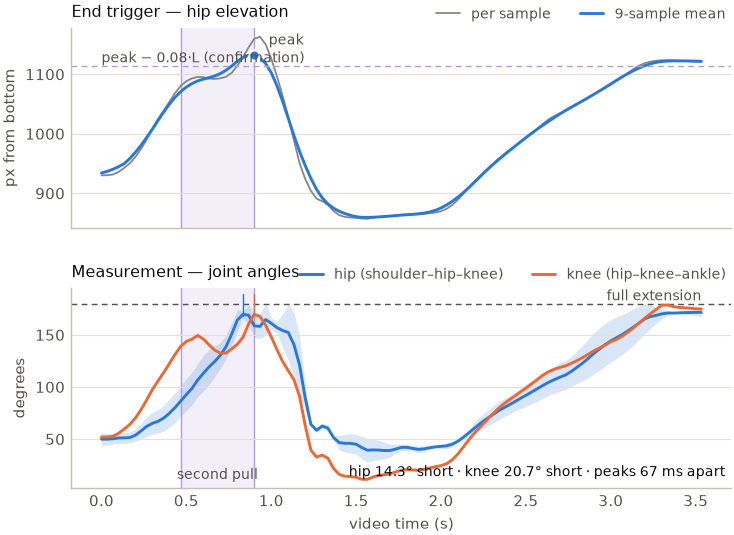

In [8]:
s0, s1 = t_at(ph2['startIdx']), t_at(ph2['endIdx'])
hip_raw = np.array([v if (v := hip_elevation(s['p'])) is not None else np.nan for s in samples])
hip_sm = np.array([v if v is not None else np.nan for v in ph2['elev']])
hipS, kneeS = joint_series(samples, 0, len(samples) - 1)
ht = np.array([s['t'] for s in hipS]); hv = np.array([s['value'] for s in hipS]); hlo = np.array([s['lo'] for s in hipS]); hhi = np.array([s['hi'] for s in hipS])
kt = np.array([s['t'] for s in kneeS]); kv = np.array([s['value'] if s['value'] is not None else np.nan for s in kneeS])

fig, ax = plt.subplots(2, 1, figsize=(TEXTW, 4.6), sharex=True, gridspec_kw=dict(hspace=0.3))
ax[0].plot(T, H - hip_raw, color=C['muted'], lw=1.0, label='per sample')
ax[0].plot(T, H - hip_sm, color=C['blue'], label='9-sample mean')
ax[0].plot([s1], [H - ph2['peakElevPx']], 'o', ms=6, color=C['blue'], mec='white', mew=1.5)
ax[0].axhline(H - (ph2['peakElevPx'] + EXT_CONFIRM_RISE * L), color=C['phase'], lw=0.8, ls=(0, (4, 3)))
ax[0].text(T[0], H - (ph2['peakElevPx'] + EXT_CONFIRM_RISE * L), f'peak − {EXT_CONFIRM_RISE}·L (confirmation)', va='bottom', fontsize=7.5, color=C['ink2'])
ax[0].annotate('peak' + ('' if ph2['confirmed'] else ' (unconfirmed)'), (s1, H - ph2['peakElevPx']), (8, 6), textcoords='offset points', fontsize=7.5, color=C['ink2'])
ax[0].set_title('End trigger — hip elevation'); ax[0].set_ylabel('px from bottom'); title_legend(ax[0])

ax[1].fill_between(ht, hlo, hhi, color=C['blue'], alpha=0.18, lw=0)
ax[1].plot(ht, hv, color=C['blue'], label='hip (shoulder–hip–knee)')
ax[1].plot(kt, kv, color=C['orange'], label='knee (hip–knee–ankle)')
ax[1].set_ylim(top=195); ref_line(ax[1], 180, 'full extension', x=T[-1], ha='right')
for tp, col in ((m2['hipPeakT'], C['blue']), (m2['kneePeakT'], C['orange'])):
    if tp is not None: ax[1].axvline(tp, color=col, lw=0.8, ymin=0.86, ymax=0.97)
ax[1].set_title('Measurement — joint angles'); ax[1].set_ylabel('degrees'); ax[1].set_xlabel('video time (s)')
title_legend(ax[1])
ax[1].text(0.99, 0.06, f"hip {m2['hipDeficit']:.1f}° short · knee {m2['kneeDeficit']:.1f}° short · peaks {m2['syncGap']*1000:.0f} ms apart",
           transform=ax[1].transAxes, ha='right', fontsize=8, color=C['ink'])
for k, a in enumerate(ax): phase_band(a, s0, s1, 'second pull' if k == 1 else None, pos='bottom')
fig.savefig(FIG / 'second-pull.pdf'); plt.show()

## Appendix figures — the 2D→3D depth lift

Two figures for the appendix: the geometry the lift is built on (§A.1–A.3) and
what the sign search actually does on this clip (§A.4, A.6). Unlike everything
above, this section **imports `src/depth_backend.py`** rather than porting it —
the depth code is already Python, so the figures exercise the shipped code path.

In [9]:

import sys, types, itertools

# depth_backend is imported, not ported: unlike the smoothing and the
# diagnostics (which live in JS and have to be re-implemented here), the depth
# math is already Python, so the figures below run the SAME code the app runs.
# cv2 is stubbed because only the plate-anchor path calls it (ellipse fitting);
# every figure here uses the keypoint-lift path, which is pure numpy.
sys.modules.setdefault('cv2', types.ModuleType('cv2'))
sys.path.insert(0, str(HERE.parent / 'src'))
import depth_backend as D

DSEQ = {int(f): q[PID] for f, q in RAW.items() if PID in q}
DKP = {f: D.Scene._parse_kp(q) for f, q in DSEQ.items()}

def dep_scene(f, signs=None):
    return D.Scene(width=META['width'], height=META['height'],
                   kp2d=DKP[f], depth_signs=signs or {})

# ONE scale for the clip, straight off the shipped property. The per-frame
# projected torso is a foreshortened lower bound on the same fixed quantity —
# scaling the bone priors by it shrinks every bone exactly when the athlete
# bends over, which is the single largest error the lift used to make.
DSEQSCENE = D.Scene(width=META['width'], height=META['height'], kp2d=DKP[min(DKP)],
                    sequence={f: {'kp2d': k, 'equipment': None} for f, k in DKP.items()})
DSCALE = DSEQSCENE.clip_torso_px
DPERFRAME = np.array([D._torso_px(k) for k in DKP.values()])

def dep_lift(f, signs, scale=None):
    """One frame -> (17,3) joints in pixels, under a given sign table."""
    sc = scale or DSCALE
    J, _ = D._bone_length_lift(dep_scene(f, signs), scale_px=sc)
    return J, sc

# Frames with both legs solved, and the deepest one (lowest hip) as the
# representative: the sign question is hardest, and matters most, at the catch.
DLEGS = (D.L_KNE, D.R_KNE, D.L_ANK, D.R_ANK)
DFRAMES = [f for f in sorted(DSEQ) if all(dep_scene(f).seen[i] for i in DLEGS)]
DREP = max(DFRAMES, key=lambda f: dep_scene(f).kp2d[[D.L_HIP, D.R_HIP], 1].mean())
print(f'{len(DFRAMES)} frames with both legs solved; representative (deepest) = {DREP}')
print(f'clip torso scale = {DSCALE:.0f} px; per-frame projection runs '
      f'{DPERFRAME.min():.0f}..{DPERFRAME.max():.0f} px '
      f'({DPERFRAME.max() / DPERFRAME.min():.2f}x)')
print('bone priors [torso]:', {f'{a}->{b}': v for (a, b), v in list(D._BONE_RATIO.items())[:4]},
      f'| shoulder {D.SHOULDER_WIDTH}, hip {D.HIP_WIDTH}')


107 frames with both legs solved; representative (deepest) = 46
clip torso scale = 246 px; per-frame projection runs 141..251 px (1.78x)
bone priors [torso]: {'11->13': 0.85, '13->15': 0.85, '12->14': 0.85, '14->16': 0.85} | shoulder 0.85, hip 0.72


### Figure 4 — the three pieces of geometry

(a) A bone of known 3D length $L$ measured at screen length $\ell$ must spend
the difference in depth. (b) That triangle has two solutions and the image
cannot tell them apart — one bit per joint, unobservable. (c) A bumper plate is
a circle of known diameter, so its fitted ellipse hands over both the metric
scale and the bar's tilt out of the image plane.

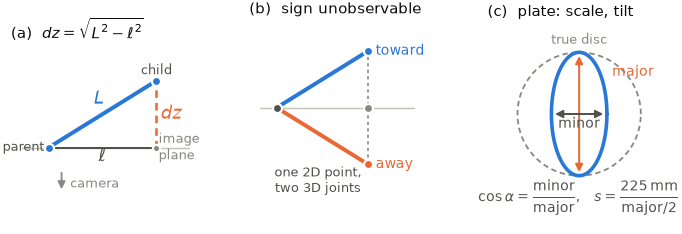

In [10]:

fig, ax = plt.subplots(1, 3, figsize=(TEXTW, 2.15), gridspec_kw=dict(wspace=0.30))
for a in ax:
    a.set_axis_off(); a.set_aspect('equal'); a.grid(False)

# (a) foreshortening: the right triangle the whole lift rests on, seen from above
a = ax[0]
l, dz = 1.0, 0.62
a.axhline(0, color=C['axis'], lw=0.8, xmin=0.06, xmax=0.97)
a.text(1.02, 0.0, 'image\nplane', fontsize=7, color=C['muted'], va='center')
a.plot([0, l], [0, dz], color=C['blue'], lw=2.2, solid_capstyle='round', zorder=3)
a.plot([0, l], [0, 0], color=C['ink2'], lw=1.1, zorder=2)
a.plot([l, l], [0, dz], color=C['orange'], lw=1.4, ls=(0, (3, 2)), zorder=2)
a.plot([0, l], [0, dz], 'o', ms=5, color=C['blue'], mec='white', mew=1.2, zorder=4)
a.plot([l], [0], 'o', ms=4, color=C['muted'], mec='white', mew=1.2, zorder=4)
a.text(0.42, 0.40, '$L$', color=C['blue'], fontsize=10)
a.text(0.5, -0.13, '$\\ell$', color=C['ink2'], fontsize=10, ha='center')
a.text(l + 0.04, dz / 2, '$dz$', color=C['orange'], fontsize=10, va='center')
a.text(-0.04, 0.0, 'parent', fontsize=7, color=C['ink2'], ha='right', va='center')
a.text(l, dz + 0.06, 'child', fontsize=7, color=C['ink2'], ha='center')
a.annotate('', xy=(0.12, -0.42), xytext=(0.12, -0.2),
           arrowprops=dict(arrowstyle='-|>', color=C['muted'], lw=1))
a.text(0.2, -0.34, 'camera', fontsize=7, color=C['muted'], va='center')
a.set_title('(a)  $dz=\\sqrt{L^2-\\ell^2}$', pad=4, fontsize=8.5)
a.set_xlim(-0.35, 1.35); a.set_ylim(-0.55, 0.95)

# (b) the same triangle has two solutions, and the image cannot separate them
a = ax[1]
a.axhline(0, color=C['axis'], lw=0.8, xmin=0.06, xmax=0.9)
for s, col, lab in ((+1, C['blue'], 'toward'), (-1, C['orange'], 'away')):
    a.plot([0, l], [0, s * dz], color=col, lw=2.2, solid_capstyle='round', zorder=3)
    a.plot([l], [s * dz], 'o', ms=5, color=col, mec='white', mew=1.2, zorder=4)
    a.text(l + 0.08, s * dz, lab, fontsize=7.5, color=col, va='center')
a.plot([l, l], [-dz, dz], color=C['muted'], lw=0.9, ls=(0, (2, 2)), zorder=1)
a.plot([0], [0], 'o', ms=5, color=C['ink2'], mec='white', mew=1.2, zorder=4)
a.plot([l], [0], 'o', ms=5, color=C['muted'], mec='white', mew=1.2, zorder=4)
a.text(l * 0.45, -dz - 0.30, 'one 2D point,\ntwo 3D joints', fontsize=7, color=C['ink2'], ha='center')
a.set_title('(b)  sign unobservable', pad=4, fontsize=8.5)
a.set_xlim(-0.3, 1.7); a.set_ylim(-1.35, 0.95)

# (c) the plate: a circle of known size, so its ellipse gives both scale and tilt
a = ax[2]
th = np.linspace(0, 2 * np.pi, 200)
R, cosa = 0.72, 0.45
a.plot(R * np.cos(th), R * np.sin(th), color=C['muted'], lw=1.0, ls=(0, (3, 2)))
a.plot(R * cosa * np.cos(th), R * np.sin(th), color=C['blue'], lw=2.0)
a.annotate('', xy=(0, R), xytext=(0, -R), arrowprops=dict(arrowstyle='<|-|>', color=C['orange'], lw=1.1))
a.annotate('', xy=(R * cosa, 0), xytext=(-R * cosa, 0), arrowprops=dict(arrowstyle='<|-|>', color=C['ink2'], lw=1.1))
a.text(R * cosa + 0.06, R * 0.62, 'major', fontsize=7.5, color=C['orange'])
a.text(0, -0.16, 'minor', fontsize=7.5, color=C['ink2'], ha='center')
a.text(0, -R - 0.30, '$\\cos\\alpha=\\dfrac{\\mathrm{minor}}{\\mathrm{major}}$,'
       '   $s=\\dfrac{225\\,\\mathrm{mm}}{\\mathrm{major}/2}$', fontsize=8, color=C['ink2'], ha='center')
a.text(0, R + 0.10, 'true disc', fontsize=7, color=C['muted'], ha='center')
a.set_title('(c)  plate: scale, tilt', pad=4, fontsize=8.5)
a.set_xlim(-R - 0.35, R + 0.35); a.set_ylim(-R - 0.62, R + 0.34)
fig.savefig(FIG / 'depth-geometry.pdf'); plt.show()

### Figure 5 — the sign search, and where it breaks

(a) Balance cost for the 16 mirror classes at the deepest frame; the horizontal
offset is identical for all of them, so the ranking is entirely a depth
judgement. (b) The winner seen from above — and its feet are nearly two torso
lengths apart in depth, which is not what the video shows. (c) The reason: with
the ankle's sign tied to the knee's, no candidate at any frame can bring the
feet close together. Freeing that bit roughly thirds the floor.

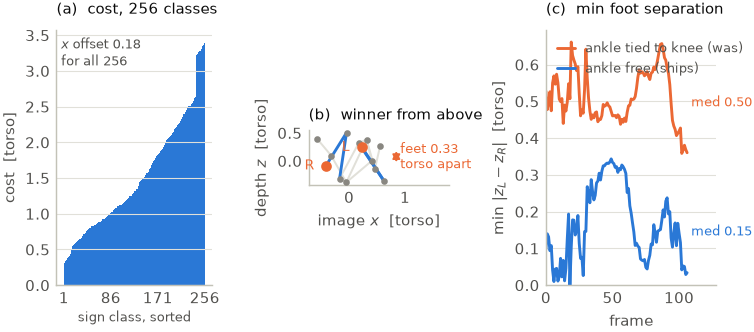

256 distinct poses; winner +-+++-++- (trunk, L/R elbow, L/R wrist, L/R knee, L/R ankle), clip cost 0.306 vs 0.317 for the runner-up
  at frame 46: depth imbalance 0.005
  its feet sit 0.33 torso apart in depth
  horizontal offset is 0.183 for every class (1 distinct value over 24 sampled) — all the evidence is in z
  min foot separation over the clip: tied 0.50 (best 0.36), free 0.15 (best 0.00) torso

solver: depth direction inferred from 256 arrangements over 35 of 107 frames (the steadiest ones): left elbow, left knee, right ankle away from camera, the rest toward. Body's mean sits 0.03 torso off the feet in depth and the feet 0.28 apart; next arrangement scores 0.010 worse. The front/back mirror of this is equally balanced — flip everything if the figure faces the wrong way


In [11]:

# --- the sign search, as shipped vs as it used to be ------------------------
# The app now searches every limb joint: trunk, both elbows, both wrists, both
# knees, both ankles = 2**9 assignments, 256 once mirrors are folded out.
# It used to tie each distal joint to its parent (ankle follows knee, wrist
# follows elbow), searching 2**5 = 32. That rule is correct for a straight limb
# and backwards for a flexed one, which is most of a lift.
DFREE = D._SIGN_FREE
DTIED = (D.TORSO_SIGN_KEY, D.L_ELB, D.R_ELB, D.L_KNE, D.R_KNE)
DFOLLOWS = {D.L_WRI: D.L_ELB, D.R_WRI: D.R_ELB, D.L_ANK: D.L_KNE, D.R_ANK: D.R_KNE}

def tied_expand(sg):
    """The old rule: distal joints inherit their parent's sign."""
    out = {k: sg[k] for k in DTIED}
    for child, parent in DFOLLOWS.items():
        out[child] = out[parent]
    return D.expand_signs(out)

# --- every distinct pose, scored by the objective the app uses ---------------
# score_signs() is the shipped scorer, called here rather than re-implemented,
# so panel (a) ranks candidates exactly the way the solver does. Ranking by
# balance alone would not: at a single frame it is very nearly degenerate
# (top two within 0.001 torso), and the arrangement it happens to pick puts the
# feet 3.3 torso apart. The stance term is what breaks that tie.
SCORED = D.score_signs(DSEQSCENE)
SS, SCOST = SCORED['S'], SCORED['cost']
SORDER = np.argsort(SCOST)

DROWS = []
for i in SORDER:
    sg = {j: int(SS[i, D._SLOT[j]]) for j in DFREE}
    DROWS.append(dict(signs=sg, cost=float(SCOST[i]),
                      lab=''.join('+' if sg[k] > 0 else '-' for k in DFREE)))
WIN = DROWS[0]
WIN['J'], WIN['sc'] = dep_lift(DREP, D.expand_signs(WIN['signs']))
WIN['bx'], WIN['bz'] = D._balance(WIN['J'], WIN['sc'])
WIN['spread'] = abs(WIN['J'][D.L_ANK, 2] - WIN['J'][D.R_ANK, 2]) / WIN['sc']
# the in-plane offset is candidate-independent; check that on a sample
BX = {round(D._balance(dep_lift(DREP, D.expand_signs(r['signs']))[0], WIN['sc'])[0], 6)
      for r in DROWS[:24]}

# --- how close can the feet get, tied vs free ------------------------------
# Sweep both schemes over every frame and keep the SMALLEST foot separation
# each can reach. This is the measurement the tied rule fails: it cannot put
# the feet together at all in the bottom of the catch.
_combos = [dict(zip(DFREE, b)) for b in itertools.product((1, -1), repeat=len(DFREE))]
tied_min, free_min = [], []
for f in DFRAMES:
    tm, fm = [], []
    for sg in _combos:
        J, _ = dep_lift(f, D.expand_signs(sg))
        d = abs(J[D.L_ANK, 2] - J[D.R_ANK, 2]) / DSCALE
        fm.append(d)
        if all(sg[c] == sg[p] for c, p in DFOLLOWS.items()):
            tm.append(d)
    tied_min.append(min(tm)); free_min.append(min(fm))

fig = plt.figure(figsize=(TEXTW, 2.55))
gs = fig.add_gridspec(1, 3, width_ratios=[1.05, 0.95, 1.15], wspace=0.62)
a0, a1, a2 = (fig.add_subplot(g) for g in gs)

a0.bar(range(len(DROWS)), [r['cost'] for r in DROWS],
       color=[C['orange'] if r is WIN else C['blue'] for r in DROWS], width=1.0)
a0.set_xticks([0, 85, 170, 255]); a0.set_xticklabels(['1', '86', '171', '256'])
a0.set_ylabel('cost  [torso]')
a0.set_xlabel('sign class, sorted', fontsize=7, labelpad=2)
a0.set_title(f'(a)  cost, {len(DROWS)} classes', fontsize=8.5, pad=9)
a0.text(0.03, 0.97, f"$x$ offset {WIN['bx']:.2f}\nfor all {len(DROWS)}",
        transform=a0.transAxes, fontsize=7, color=C['ink2'], va='top')

J = WIN['J'] / WIN['sc']
LEGEDGE = [(D.L_HIP, D.L_KNE), (D.L_KNE, D.L_ANK), (D.R_HIP, D.R_KNE), (D.R_KNE, D.R_ANK)]
for e in D.EDGES:
    p, c = e[0], e[1]
    if np.all(np.isfinite(J[p])) and np.all(np.isfinite(J[c])):
        leg = (p, c) in LEGEDGE or (c, p) in LEGEDGE
        a1.plot([J[p, 0], J[c, 0]], [J[p, 2], J[c, 2]], color=C['blue'] if leg else C['grid'],
                lw=1.6 if leg else 1.1, zorder=2 if leg else 1)
ok = np.all(np.isfinite(J), axis=1)
a1.scatter(J[ok, 0], J[ok, 2], s=7, color=C['muted'], zorder=3)
for i, lab in ((D.L_ANK, 'L'), (D.R_ANK, 'R')):
    a1.scatter([J[i, 0]], [J[i, 2]], s=24, color=C['orange'], zorder=4)
    a1.annotate(lab, (J[i, 0], J[i, 2]), (-9, 0), textcoords='offset points',
                fontsize=7.5, color=C['orange'], va='center', ha='center')
xa = float(np.nanmax(J[:, 0])) + 0.22
za, zb = J[D.L_ANK, 2], J[D.R_ANK, 2]
a1.annotate('', xy=(xa, za), xytext=(xa, zb), arrowprops=dict(arrowstyle='<|-|>', color=C['orange'], lw=1))
a1.text(xa + 0.07, (za + zb) / 2, f"feet {WIN['spread']:.2f}\ntorso apart",
        fontsize=7, color=C['orange'], ha='left', va='center')
a1.set_xlim(float(np.nanmin(J[:, 0])) - 0.15, xa + 0.95)
a1.set_aspect('equal'); a1.grid(False)
a1.set_xlabel('image $x$  [torso]'); a1.set_ylabel('depth $z$  [torso]')
a1.set_title('(b)  winner from above', fontsize=8.5)

a2.plot(DFRAMES, tied_min, color=C['orange'], label='ankle tied to knee (was)')
a2.plot(DFRAMES, free_min, color=C['blue'], label='ankle free (ships)')
a2.set_xlabel('frame'); a2.set_ylabel('min $|z_L-z_R|$  [torso]'); a2.set_ylim(0, None)
a2.set_xlim(DFRAMES[0], DFRAMES[-1] + 22)
a2.set_title('(c)  min foot separation', fontsize=8.5, pad=9)
a2.legend(loc='upper left', fontsize=7, handlelength=1.4)
a2.text(DFRAMES[-1], np.median(tied_min), f' med {np.median(tied_min):.2f}', fontsize=7, color=C['orange'], va='center')
a2.text(DFRAMES[-1], np.median(free_min), f' med {np.median(free_min):.2f}', fontsize=7, color=C['blue'], va='center')
fig.savefig(FIG / 'depth-signs.pdf'); plt.show()

print(f"{len(DROWS)} distinct poses; winner {WIN['lab']} "
      f"(trunk, L/R elbow, L/R wrist, L/R knee, L/R ankle), clip cost "
      f"{WIN['cost']:.3f} vs {DROWS[1]['cost']:.3f} for the runner-up")
print(f"  at frame {DREP}: depth imbalance {WIN['bz']:.3f}")
print(f"  its feet sit {WIN['spread']:.2f} torso apart in depth")
print(f"  horizontal offset is {WIN['bx']:.3f} for every class "
      f"({len(BX)} distinct value over 24 sampled) — all the evidence is in z")
print(f"  min foot separation over the clip: tied {np.median(tied_min):.2f} (best {min(tied_min):.2f}), "
      f"free {np.median(free_min):.2f} (best {min(free_min):.2f}) torso")

# What the solver actually returns for this clip, through the shipped entry point.
_signs, _note, _margin = D.infer_depth_signs(DSEQSCENE)
print('\nsolver:', _note)
